# Experiment 6 - Generative Adversarial Network (GAN) for Image Generation


In [ ]:
import tensorflow as tf, numpy as np, matplotlib.pyplot as plt
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist
tf.random.set_seed(7); np.random.seed(7)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [ ]:
(x_train,_),(_,_) = mnist.load_data()
x_train = (x_train.astype("float32") - 127.5) / 127.5
x_train = x_train.reshape((-1,28,28,1))
# Use a subset for a practical Colab demonstration. Increase SUBSET_SIZE for a longer run.
SUBSET_SIZE = 20000
x_train = x_train[:SUBSET_SIZE]
print("Training images:", x_train.shape, "pixel range:", x_train.min(), x_train.max())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (20000, 28, 28, 1) pixel range: -1.0 1.0


In [ ]:
LATENT_DIM = 100
generator = tf.keras.Sequential([
    layers.Input(shape=(LATENT_DIM,)),
    layers.Dense(7*7*128, use_bias=False),
    layers.BatchNormalization(), layers.LeakyReLU(),
    layers.Reshape((7,7,128)),
    layers.Conv2DTranspose(64, 4, strides=2, padding="same", use_bias=False),
    layers.BatchNormalization(), layers.LeakyReLU(),
    layers.Conv2DTranspose(1, 4, strides=2, padding="same", activation="tanh")
], name="Generator")

discriminator = tf.keras.Sequential([
    layers.Input(shape=(28,28,1)),
    layers.Conv2D(64, 4, strides=2, padding="same"),
    layers.LeakyReLU(), layers.Dropout(0.3),
    layers.Conv2D(128, 4, strides=2, padding="same"),
    layers.LeakyReLU(), layers.Dropout(0.3),
    layers.Flatten(), layers.Dense(1)
], name="Discriminator")

generator.summary(); discriminator.summary()

Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 784,641 (2.99 MB)

 Trainable params: 771,969 (2.94 MB)

 Non-trainable params: 12,672 (49.50 KB)

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,561 (541.25 KB)

 Trainable params: 138,561 (541.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)
g_optimizer = tf.keras.optimizers.Adam(1e-4)
d_optimizer = tf.keras.optimizers.Adam(1e-4)

def discriminator_loss(real_logits, fake_logits):
    real_loss = cross_entropy(tf.ones_like(real_logits), real_logits)
    fake_loss = cross_entropy(tf.zeros_like(fake_logits), fake_logits)
    return real_loss + fake_loss

def generator_loss(fake_logits):
    return cross_entropy(tf.ones_like(fake_logits), fake_logits)

@tf.function
def train_step(real_images):
    noise = tf.random.normal([tf.shape(real_images)[0], LATENT_DIM])
    with tf.GradientTape() as gt, tf.GradientTape() as dt:
        fake_images = generator(noise, training=True)
        real_logits = discriminator(real_images, training=True)
        fake_logits = discriminator(fake_images, training=True)
        g_loss = generator_loss(fake_logits)
        d_loss = discriminator_loss(real_logits, fake_logits)
    g_grads = gt.gradient(g_loss, generator.trainable_variables)
    d_grads = dt.gradient(d_loss, discriminator.trainable_variables)
    g_optimizer.apply_gradients(zip(g_grads, generator.trainable_variables))
    d_optimizer.apply_gradients(zip(d_grads, discriminator.trainable_variables))
    return g_loss, d_loss

def show_generated(epoch_label, n=16):
    noise=tf.random.normal([n,LATENT_DIM])
    imgs=generator(noise,training=False)
    imgs=(imgs+1)/2
    fig,axes=plt.subplots(4,4,figsize=(5,5))
    for ax,img in zip(axes.flat,imgs):
        ax.imshow(img[:,:,0],cmap="gray"); ax.axis("off")
    plt.suptitle(epoch_label); plt.tight_layout(); plt.show()

Epoch 01/10 | Generator loss=1.0310 | Discriminator loss=0.6964


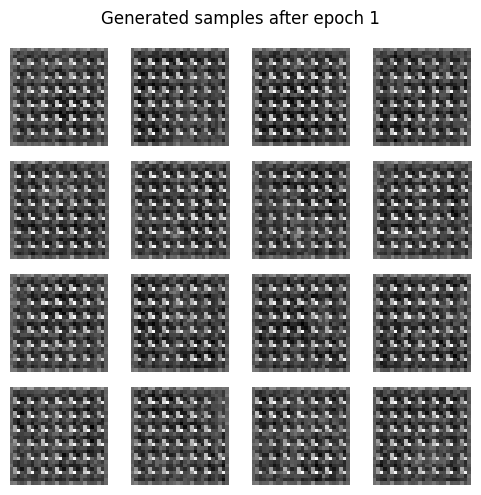

Epoch 02/10 | Generator loss=2.1882 | Discriminator loss=0.2721
Epoch 03/10 | Generator loss=1.0940 | Discriminator loss=0.9913
Epoch 04/10 | Generator loss=1.0928 | Discriminator loss=0.9403
Epoch 05/10 | Generator loss=1.0824 | Discriminator loss=1.0465
Epoch 06/10 | Generator loss=0.9175 | Discriminator loss=1.2453


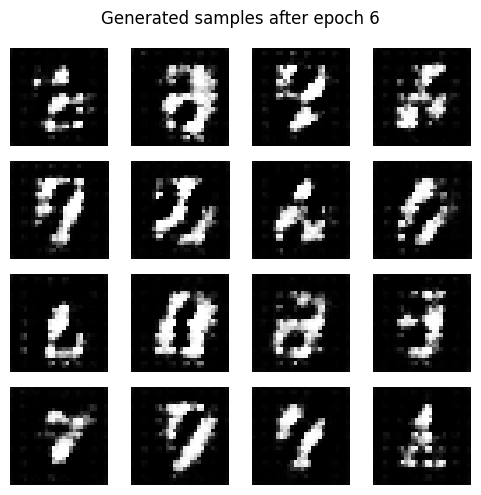

Epoch 07/10 | Generator loss=0.9775 | Discriminator loss=1.1865
Epoch 08/10 | Generator loss=0.9191 | Discriminator loss=1.2153
Epoch 09/10 | Generator loss=0.9066 | Discriminator loss=1.2410
Epoch 10/10 | Generator loss=0.9170 | Discriminator loss=1.2042


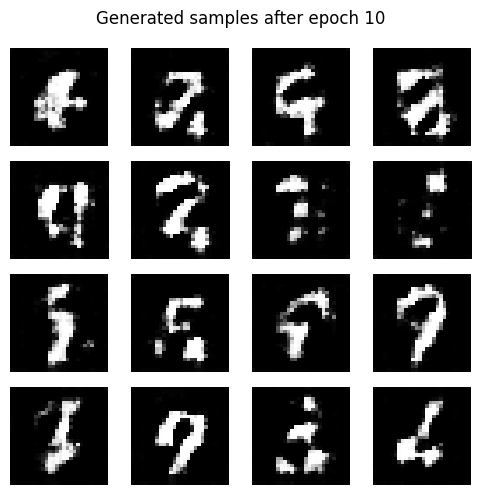

In [ ]:
EPOCHS = 10
BATCH_SIZE = 128
dataset = tf.data.Dataset.from_tensor_slices(x_train).shuffle(10000).batch(BATCH_SIZE, drop_remainder=True).prefetch(tf.data.AUTOTUNE)
g_losses, d_losses = [], []
for epoch in range(EPOCHS):
    gl, dl = [], []
    for batch in dataset:
        g_loss, d_loss = train_step(batch)
        gl.append(float(g_loss)); dl.append(float(d_loss))
    g_losses.append(np.mean(gl)); d_losses.append(np.mean(dl))
    print(f"Epoch {epoch+1:02d}/{EPOCHS} | Generator loss={g_losses[-1]:.4f} | Discriminator loss={d_losses[-1]:.4f}")
    if epoch in [0, EPOCHS//2, EPOCHS-1]:
        show_generated(f"Generated samples after epoch {epoch+1}")

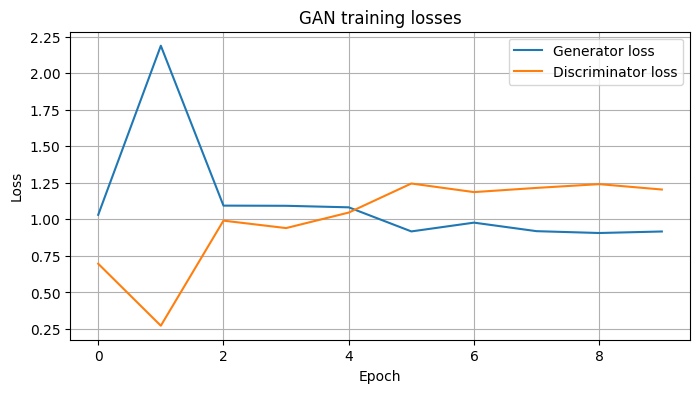

In [ ]:
plt.figure(figsize=(8,4))
plt.plot(g_losses,label="Generator loss"); plt.plot(d_losses,label="Discriminator loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("GAN training losses"); plt.legend(); plt.grid(True); plt.show()

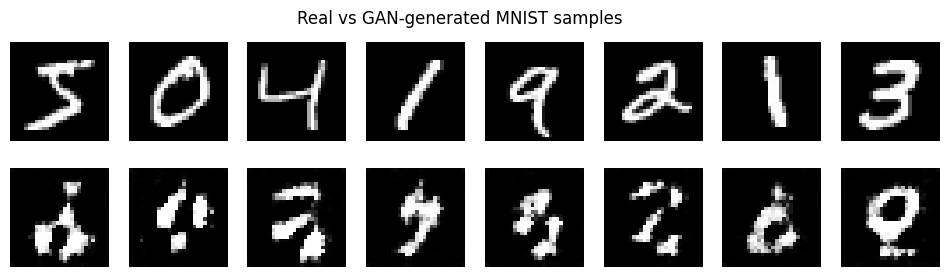

In [ ]:
# Compare real examples and final generated examples.
fig, axes=plt.subplots(2,8,figsize=(12,3))
for i in range(8):
    axes[0,i].imshow((x_train[i,:,:,0]+1)/2,cmap="gray"); axes[0,i].axis("off")
fake=generator(tf.random.normal([8,LATENT_DIM]),training=False)
for i in range(8):
    axes[1,i].imshow((fake[i,:,:,0].numpy()+1)/2,cmap="gray"); axes[1,i].axis("off")
axes[0,0].set_ylabel("Real"); axes[1,0].set_ylabel("Synthetic")
plt.suptitle("Real vs GAN-generated MNIST samples"); plt.show()